# 03 — Tạo đặc trưng

Tạo feature từ dữ liệu cleaned và cache của EDA. Mỗi dòng ứng với một cặp cửa hàng–mặt hàng, mốc dự báo `T` và bước `h = 1..16`.

Lịch sử chỉ dùng dữ liệu đến `T`. Ngày mục tiêu là `T + h`. Target học là `log1p(clip(unit_sales, 0))`, trọng số hàng mau hỏng là 1,25.

Ngày cặp không có dòng được coi là 0; mẫu số lịch sử không tính ngày trước khi cặp xuất hiện. Đây là giả định cần kiểm chứng, không phân biệt hoàn toàn không bán và không niêm yết.

Mỗi mốc được xử lý và lưu riêng để giảm RAM. Khuyến mãi tương lai và cặp mới có giới hạn riêng, nêu trong các phần dưới.


## 1. Thiết lập

Khai báo thư viện, seed và các thư mục dữ liệu, feature, báo cáo.


In [27]:
import gc
import json
import math
import time
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.dataset as ds
import pyarrow.parquet as pq
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)


def find_project_root(start: Path) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "data" / "raw" / "train.csv").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy data/raw/train.csv. Hãy mở notebook trong repository của project.")


PROJECT_ROOT = find_project_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURE_DIR = PROCESSED_DIR / "features"
CACHE_DIR = PROJECT_ROOT / "data" / "interim" / "eda_cache"
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_TABLE_DIR = REPORT_DIR / "table"
for directory in (FEATURE_DIR, REPORT_TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Feature dir  :", FEATURE_DIR)
try:
    import psutil
    print(f"Available RAM: {psutil.virtual_memory().available / 1024**3:.2f} GB")
except ImportError:
    psutil = None

Project root : D:\Machine-learning-project-Grocery-sales-forecast
Feature dir  : D:\Machine-learning-project-Grocery-sales-forecast\data\processed\features
Available RAM: 1.65 GB


## 2. Cấu hình cửa sổ và số dòng

Lịch sử dài 224 ngày, horizon 16 ngày; mốc train cách nhau 13 ngày để phủ các thứ trong tuần. Giới hạn khoảng 3 triệu dòng train bằng lấy mẫu cặp.

Các mốc có khoảng mục tiêu hoặc 28 ngày lịch sử chạm giai đoạn động đất được loại. Cửa sổ lịch sử dài hơn vẫn có thể chứa ảnh hưởng của giai đoạn này.


In [28]:
# ----------------------------------------------------------------- đọc snapshot của notebook 00 (nếu có)
snapshot_path = REPORT_DIR / "00_environment_snapshot.json"
if snapshot_path.exists():
    snapshot = json.loads(snapshot_path.read_text(encoding="utf-8"))
    HORIZON = int(snapshot["forecast"]["horizon_days"])
    TEST_ORIGIN = pd.Timestamp(snapshot["forecast"]["expected_train_end"])
    RECOMMENDED_CHUNK_SIZE = int(snapshot["chunk"]["recommended_chunk_size"])
    PERISHABLE_WEIGHT = float(snapshot["metric"]["perishable_weight"])
    print("Đã đọc snapshot của notebook 00.")
else:
    snapshot = None
    HORIZON, TEST_ORIGIN, RECOMMENDED_CHUNK_SIZE, PERISHABLE_WEIGHT = 16, pd.Timestamp("2017-08-15"), 250_000, 1.25
    print("Không thấy snapshot của notebook 00; dùng giá trị mặc định.")

# ----------------------------------------------------------------- cấu hình cửa sổ lịch sử
LOOKBACK = 224                       # số ngày lịch sử dày cho mỗi mốc (32 tuần)
WINDOWS = [3, 7, 14, 28, 56, 112, 224]
ACT_WINDOWS = [7, 14, 28, 56, 112]
MEANPOS_WINDOWS = [28, 112]
DOW_OCCURRENCES = [4, 8, 16]         # số lần xuất hiện của cùng thứ trong tuần

# ----------------------------------------------------------------- cấu hình các mốc
LAST_TRAIN_ORIGIN = TEST_ORIGIN - pd.Timedelta(days=HORIZON)     # mốc cuối cùng có nhãn đầy đủ trong train
ORIGIN_STEP_DAYS = 13                # nguyên tố cùng nhau với 7
TRAIN_ORIGIN_START = pd.Timestamp("2015-06-01")
SEASONAL_VALID_ORIGIN = pd.Timestamp("2016-08-15")               # cùng thời điểm mùa vụ năm trước

QUAKE_START, QUAKE_END = pd.Timestamp("2016-04-16"), pd.Timestamp("2016-05-15")
QUAKE_LOOKBACK_EXCLUDE_DAYS = 28

# ----------------------------------------------------------------- ngân sách dữ liệu
TARGET_TRAIN_ROWS = 3_000_000        # tổng số dòng của các mốc huấn luyện (giảm nếu thiếu RAM ở notebook 04)
VALID_PAIR_FRAC = {"valid_last16": 1.0, "valid_seasonal": 0.5}
FORCE_REBUILD = False                # True: dựng lại các file đã tồn tại

# ----------------------------------------------------------------- hằng số khác
PROMO_TRACKING_START = pd.Timestamp("2014-04-01")   # mốc thiếu khuyến mãi được kiểm tra ở notebook 02
KEY_MUL = 10_000_000                 # khóa cặp = store * KEY_MUL + item (item_nbr < 1e7)
STATUS_NAMES = {0: "cặp cũ, có bán trong 28 ngày", 1: "cặp cũ, ngừng bán > 28 ngày",
                2: "cặp mới, item đã có", 3: "cặp mới, item chưa từng có"}

assert math.gcd(ORIGIN_STEP_DAYS, 7) == 1, "ORIGIN_STEP_DAYS phải nguyên tố cùng nhau với 7"
assert LOOKBACK >= max(WINDOWS)
print(f"HORIZON={HORIZON} | TEST_ORIGIN={TEST_ORIGIN.date()} | LAST_TRAIN_ORIGIN={LAST_TRAIN_ORIGIN.date()} | LOOKBACK={LOOKBACK}")

Đã đọc snapshot của notebook 00.
HORIZON=16 | TEST_ORIGIN=2017-08-15 | LAST_TRAIN_ORIGIN=2017-07-30 | LOOKBACK=224


## 3. Metric

Dùng NWRMSLE như notebook 00. Các ví dụ nhỏ kiểm tra công thức trước khi xử lý dữ liệu.


In [29]:
def nwrmsle(y_true, y_pred, perishable, perishable_weight=PERISHABLE_WEIGHT):
    y_true = np.clip(np.asarray(y_true, dtype="float64"), 0, None)
    y_pred = np.clip(np.asarray(y_pred, dtype="float64"), 0, None)
    w = np.where(np.asarray(perishable) == 1, perishable_weight, 1.0)
    return float(np.sqrt(np.sum(w * (np.log1p(y_pred) - np.log1p(y_true)) ** 2) / np.sum(w)))


assert nwrmsle([0, 3], [0, 3], [0, 1]) == 0.0
assert abs(nwrmsle([1], [3], [0]) - np.log(2)) < 1e-12
print("nwrmsle(): PASS")

nwrmsle(): PASS


## 4. Dữ liệu đầu vào

Đọc các bảng cleaned và cache `pair`, `store_day` của EDA.


In [30]:
required = ["train_cleaned.parquet", "test_cleaned.parquet", "stores_cleaned.parquet", "items_cleaned.parquet",
            "oil_cleaned.parquet", "holidays_events_cleaned.parquet", "transactions_cleaned.parquet"]
missing = [n for n in required if not (PROCESSED_DIR / n).exists()]
if missing:
    raise FileNotFoundError(f"Thiếu file đã làm sạch: {missing}. Hãy chạy notebook 02 trước.")

stores = pd.read_parquet(PROCESSED_DIR / "stores_cleaned.parquet")
items = pd.read_parquet(PROCESSED_DIR / "items_cleaned.parquet")
oil = pd.read_parquet(PROCESSED_DIR / "oil_cleaned.parquet")
holidays = pd.read_parquet(PROCESSED_DIR / "holidays_events_cleaned.parquet")
transactions = pd.read_parquet(PROCESSED_DIR / "transactions_cleaned.parquet")

for frame, col in ((oil, "date"), (holidays, "date"), (transactions, "date")):
    frame[col] = pd.to_datetime(frame[col])

# ----------------------------------------------------------------- cache của notebook 01
cache_ext = "parquet" if all((CACHE_DIR / f"{n}.parquet").exists() for n in ("pair", "store_day")) else "csv"
for name in ("pair", "store_day"):
    if not (CACHE_DIR / f"{name}.{cache_ext}").exists():
        raise FileNotFoundError(f"Thiếu cache {name} ở {CACHE_DIR}. Hãy chạy mục 1.1 của notebook 01.")


def read_cache(name):
    path = CACHE_DIR / f"{name}.{cache_ext}"
    return pd.read_parquet(path) if cache_ext == "parquet" else pd.read_csv(path)


pair_tbl = read_cache("pair")[["store_nbr", "item_nbr", "first_date"]].copy()
pair_tbl["first_date"] = pd.to_datetime(pair_tbl["first_date"])
pair_tbl["key"] = pair_tbl["store_nbr"].astype("int64") * KEY_MUL + pair_tbl["item_nbr"].astype("int64")
pair_tbl = pair_tbl.sort_values("key").reset_index(drop=True)

store_day = read_cache("store_day")
store_day["date"] = pd.to_datetime(store_day["date"])

print(f"stores={len(stores)} | items={len(items)} | pairs (cache)={len(pair_tbl):,} | store-day (cache)={len(store_day):,}")
print(f"oil={len(oil)} | holidays={len(holidays)} | transactions={len(transactions):,}")

stores=54 | items=4100 | pairs (cache)=174,685 | store-day (cache)=83,606
oil=1218 | holidays=350 | transactions=83,488


## 5. Chỉ mục ngày của Parquet

Đọc khoảng ngày của từng row group để chọn đúng phần train cần cho mỗi mốc.


In [31]:
TRAIN_PQ = PROCESSED_DIR / "train_cleaned.parquet"
pf = pq.ParquetFile(TRAIN_PQ)
date_col_idx = pf.schema_arrow.names.index("date")

records = []
for i in range(pf.num_row_groups):
    rg = pf.metadata.row_group(i)
    st = rg.column(date_col_idx).statistics
    if st is not None and st.has_min_max:
        lo, hi = pd.Timestamp(st.min), pd.Timestamp(st.max)
    else:                                              # dự phòng: đọc cột date
        col = pd.to_datetime(pf.read_row_group(i, columns=["date"]).column("date").to_pandas())
        lo, hi = col.min(), col.max()
    records.append((i, lo, hi, rg.num_rows))

rg_df = pd.DataFrame(records, columns=["rg", "min_date", "max_date", "rows"])
is_sorted = bool((rg_df["min_date"].iloc[1:].to_numpy() >= rg_df["max_date"].iloc[:-1].to_numpy()).all())
TRAIN_FIRST_DATE, TRAIN_LAST_DATE = rg_df["min_date"].min(), rg_df["max_date"].max()

print(f"Row groups: {len(rg_df):,} | tổng dòng: {int(rg_df['rows'].sum()):,} | file sắp theo ngày: {is_sorted}")
print(f"Phạm vi ngày train: {TRAIN_FIRST_DATE.date()} → {TRAIN_LAST_DATE.date()}")
assert is_sorted, "File train không sắp theo ngày; chỉ mục row group không áp dụng được."
assert TRAIN_LAST_DATE == TEST_ORIGIN, f"Ngày cuối train ({TRAIN_LAST_DATE.date()}) khác mốc test ({TEST_ORIGIN.date()})"

Row groups: 1,255 | tổng dòng: 125,497,040 | file sắp theo ngày: True
Phạm vi ngày train: 2013-01-01 → 2017-08-15


## 6. Mã hóa metadata

Tạo mã số cho thông tin cửa hàng và mặt hàng. Lưu ánh xạ trong `reports/03_encodings.json`.


In [32]:
store_ids = np.sort(stores["store_nbr"].unique()).astype(np.int64)
store_pos = np.full(int(store_ids.max()) + 2, -1, dtype=np.int64)
store_pos[store_ids] = np.arange(len(store_ids))
N_STORES = len(store_ids)

stores_sorted = stores.set_index("store_nbr").loc[store_ids].reset_index()


def codes_of(series):
    categories = sorted(pd.Series(series).dropna().astype(str).unique())
    return categories, {c: i for i, c in enumerate(categories)}


type_cats, type_map = codes_of(stores_sorted["type"])
state_cats, state_map = codes_of(stores_sorted["state"])
city_cats, city_map = codes_of(stores_sorted["city"])
family_cats, family_map = codes_of(items["family"])

store_static = pd.DataFrame({
    "store_nbr": stores_sorted["store_nbr"].astype("int64"),
    "store_type": stores_sorted["type"].astype(str).map(type_map).astype("int8"),
    "store_cluster": stores_sorted["cluster"].astype("int16"),
    "store_state": stores_sorted["state"].astype(str).map(state_map).astype("int16"),
    "store_city": stores_sorted["city"].astype(str).map(city_map).astype("int16"),
})
item_static = items[["item_nbr", "family", "class", "perishable"]].copy()
item_static["item_family"] = item_static["family"].astype(str).map(family_map).astype("int16")
item_static["item_class"] = item_static["class"].astype("int32")
item_static["perishable"] = item_static["perishable"].astype("int8")
item_static = item_static.drop(columns=["family", "class"]).sort_values("item_nbr").reset_index(drop=True)

encodings = {"store_type": type_cats, "store_state": state_cats, "store_city": city_cats, "item_family": family_cats}
(REPORT_DIR / "03_encodings.json").write_text(json.dumps(encodings, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"{N_STORES} cửa hàng | {len(item_static):,} mặt hàng | {len(family_cats)} family | đã lưu reports/03_encodings.json")

54 cửa hàng | 4,100 mặt hàng | 33 family | đã lưu reports/03_encodings.json


## 7. Lịch ngày lễ

Lễ hiệu lực gồm Holiday, Additional, Bridge không bị dời và các dòng Transfer. Event và Work Day có cờ riêng ở phạm vi quốc gia.

Gộp theo ngày, phạm vi và tên địa phương trước khi gán cờ. National áp dụng toàn bộ cửa hàng; Regional theo state; Local theo city.


In [33]:
CAL0 = pd.Timestamp("2013-01-01")
hol = holidays.copy()
hol["transferred"] = hol["transferred"].astype(str).str.strip().str.lower().eq("true")
hol["is_hol"] = (hol["type"].isin(["Holiday", "Additional", "Bridge"]) & ~hol["transferred"]) | (hol["type"] == "Transfer")
hol["is_event"] = hol["type"] == "Event"
hol["is_workday"] = hol["type"] == "Work Day"

grouped = hol.groupby(["date", "locale", "locale_name"], as_index=False)[["is_hol", "is_event", "is_workday"]].max()
print(f"Gom {len(hol)} dòng holidays → {len(grouped)} nhóm (date, locale, locale_name)")

CAL1 = max(TEST_ORIGIN + pd.Timedelta(days=HORIZON), hol["date"].max())
N_CAL = (CAL1 - CAL0).days + 1

nat_hol = np.zeros(N_CAL, dtype=np.int8)
ev_nat = np.zeros(N_CAL, dtype=np.int8)
workday_nat = np.zeros(N_CAL, dtype=np.int8)
reg_hol = np.zeros((N_STORES, N_CAL), dtype=np.int8)
loc_hol = np.zeros((N_STORES, N_CAL), dtype=np.int8)

state_arr = stores_sorted["state"].astype(str).to_numpy()
city_arr = stores_sorted["city"].astype(str).to_numpy()

for r in grouped.itertuples(index=False):
    d = (r.date - CAL0).days
    if d < 0 or d >= N_CAL:
        continue
    if r.locale == "National":
        nat_hol[d] |= int(r.is_hol); ev_nat[d] |= int(r.is_event); workday_nat[d] |= int(r.is_workday)
    elif r.locale == "Regional":
        reg_hol[state_arr == str(r.locale_name), d] |= int(r.is_hol)
    elif r.locale == "Local":
        loc_hol[city_arr == str(r.locale_name), d] |= int(r.is_hol)

hol_days = np.flatnonzero(nat_hol)
all_days = np.arange(N_CAL)
nxt = np.searchsorted(hol_days, all_days, side="left")
prv = np.searchsorted(hol_days, all_days, side="right") - 1
CAP = 30
days_to_nat_hol = np.where(nxt < len(hol_days), hol_days[np.minimum(nxt, len(hol_days) - 1)] - all_days, CAP).clip(0, CAP).astype(np.int16)
days_since_nat_hol = np.where(prv >= 0, all_days - hol_days[np.maximum(prv, 0)], CAP).clip(0, CAP).astype(np.int16)

print(f"Lịch: {CAL0.date()} → {CAL1.date()} ({N_CAL} ngày) | lễ quốc gia hiệu lực: {int(nat_hol.sum())} ngày | Event: {int(ev_nat.sum())} | Work Day: {int(workday_nat.sum())}")

Gom 350 dòng holidays → 343 nhóm (date, locale, locale_name)
Lịch: 2013-01-01 → 2017-12-26 (1821 ngày) | lễ quốc gia hiệu lực: 91 ngày | Event: 55 | Work Day: 5


## 8. Feature lịch và ngày có dữ liệu

Tạo thứ, ngày, tháng, tuần, khoảng cách đến cuối tháng và các cờ lịch. `is_payday15` bằng 1 ở ngày 15 hoặc ngày cuối tháng; tên cờ không chứng minh có hiệu ứng trả lương.

Bảng store-day cho biết ngày nào có dữ liệu của từng cửa hàng.


In [34]:
def calendar_table(dates):
    d = pd.DatetimeIndex(dates)
    dim = d.days_in_month.to_numpy()
    day = d.day.to_numpy()
    year = d.year.to_numpy()
    xmas_this = pd.to_datetime(pd.DataFrame({"year": year, "month": 12, "day": 25}))
    xmas_year = np.where(d.to_numpy() > xmas_this.to_numpy(), year + 1, year)
    xmas_next = pd.to_datetime(pd.DataFrame({"year": xmas_year, "month": 12, "day": 25}))
    return pd.DataFrame({
        "dow": d.dayofweek.to_numpy().astype(np.int8),
        "dom": day.astype(np.int8),
        "month": d.month.to_numpy().astype(np.int8),
        "woy": d.isocalendar().week.to_numpy().astype(np.int8),
        "days_to_month_end": (dim - day).astype(np.int8),
        "is_payday15": ((day == 15) | (day == dim)).astype(np.int8),
        "is_jan1": ((d.month == 1) & (day == 1)).astype(np.int8),
        "is_dec24_31": ((d.month == 12) & (day >= 24)).astype(np.int8),
        "days_to_xmas": np.minimum((xmas_next.to_numpy() - d.to_numpy()) / np.timedelta64(1, "D"), 60).astype(np.int8),
    }, index=d)


store_day_exists = np.zeros((N_STORES, N_CAL), dtype=bool)
sd_pos = store_pos[store_day["store_nbr"].to_numpy().astype(np.int64)]
sd_day = (store_day["date"] - CAL0).dt.days.to_numpy()
ok = (sd_pos >= 0) & (sd_day >= 0) & (sd_day < N_CAL)
store_day_exists[sd_pos[ok], sd_day[ok]] = True

store_first_date = store_day.groupby("store_nbr")["date"].min()
print(f"store-day tồn tại: {int(store_day_exists.sum()):,} | mẫu lịch:")
display(calendar_table(pd.date_range("2017-08-16", periods=3)))

store-day tồn tại: 83,606 | mẫu lịch:


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_30692\3898522946.py:10: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "dow": d.dayofweek.to_numpy().astype(np.int8),


,dow,dom,month,woy,days_to_month_end,is_payday15,is_jan1,is_dec24_31,days_to_xmas
2017-08-16,2,16,8,33,15,0,0,0,60
2017-08-17,3,17,8,33,14,0,0,0,60
2017-08-18,4,18,8,33,13,0,0,0,60


## 9. Các mốc train và validation

V1 dùng 16 ngày cuối train. V2 dùng cùng thời điểm mùa vụ năm trước.

Mốc train chỉ hợp lệ với fold có ngày cắt `T_f` khi `T_train + 16 ngày ≤ T_f`. Các bước 04 và 05 phải giữ điều kiện này.


In [35]:
def overlaps(a0, a1, b0, b1):
    return not (a1 < b0 or a0 > b1)


# ----------------------------------------------------------------- liệt kê mốc ứng viên
candidates = []
t = LAST_TRAIN_ORIGIN
k = 0
while t >= TRAIN_ORIGIN_START:
    candidates.append((k, t))
    t = t - pd.Timedelta(days=ORIGIN_STEP_DAYS)
    k += 1

n_known_by_origin = lambda T: int((pair_tbl["first_date"] <= T).sum())

plan = []
for k, T in candidates:
    tgt0, tgt1 = T + pd.Timedelta(days=1), T + pd.Timedelta(days=HORIZON)
    quake_hit = overlaps(tgt0, tgt1, QUAKE_START, QUAKE_END) or overlaps(
        T - pd.Timedelta(days=QUAKE_LOOKBACK_EXCLUDE_DAYS - 1), T, QUAKE_START, QUAKE_END)
    role = "valid_last16" if k == 0 else "train"
    plan.append({"k": k, "origin": T, "role": role, "weekday": T.day_name(), "n_known_pairs": n_known_by_origin(T),
                 "excluded_quake": bool(quake_hit and role == "train")})

# mốc kiểm định theo mùa vụ năm trước
if pd.Timestamp(SEASONAL_VALID_ORIGIN) + pd.Timedelta(days=HORIZON) <= TEST_ORIGIN:
    plan.append({"k": -1, "origin": SEASONAL_VALID_ORIGIN, "role": "valid_seasonal", "weekday": SEASONAL_VALID_ORIGIN.day_name(),
                 "n_known_pairs": n_known_by_origin(SEASONAL_VALID_ORIGIN), "excluded_quake": False})

plan.append({"k": -2, "origin": TEST_ORIGIN, "role": "test", "weekday": TEST_ORIGIN.day_name(),
             "n_known_pairs": n_known_by_origin(TEST_ORIGIN), "excluded_quake": False})

plan_df = pd.DataFrame(plan)

# ----------------------------------------------------------------- chia ngân sách dòng huấn luyện
train_mask = (plan_df["role"] == "train") & ~plan_df["excluded_quake"]
expected_full_rows = float((plan_df.loc[train_mask, "n_known_pairs"] * HORIZON).sum())
TRAIN_PAIR_FRAC = float(min(1.0, TARGET_TRAIN_ROWS / max(expected_full_rows, 1.0)))

plan_df["pair_frac"] = np.select(
    [train_mask, plan_df["role"] == "valid_last16", plan_df["role"] == "valid_seasonal", plan_df["role"] == "test"],
    [TRAIN_PAIR_FRAC, VALID_PAIR_FRAC["valid_last16"], VALID_PAIR_FRAC["valid_seasonal"], 1.0], default=0.0)
plan_df["use"] = plan_df["pair_frac"] > 0
plan_df["est_rows"] = (plan_df["n_known_pairs"] * HORIZON * plan_df["pair_frac"]).where(plan_df["role"] != "test", other=np.nan)
plan_df["file"] = plan_df.apply(lambda r: f"{r['role']}_{r['origin'].strftime('%Y%m%d')}.parquet", axis=1)

print(f"Số mốc huấn luyện dùng: {int(train_mask.sum())} | bị loại do động đất: {int((plan_df['role'].eq('train') & plan_df['excluded_quake']).sum())}")
print(f"Tỷ lệ lấy mẫu cặp cho mốc huấn luyện: {TRAIN_PAIR_FRAC:.4f}  (mục tiêu {TARGET_TRAIN_ROWS:,} dòng)")
print("Phân bố thứ trong tuần của các mốc huấn luyện:")
display(plan_df[train_mask]["weekday"].value_counts().rename_axis("weekday").to_frame("số mốc").T)
display(plan_df[plan_df["role"] != "train"][["role", "origin", "weekday", "n_known_pairs", "pair_frac", "est_rows", "file"]])

Số mốc huấn luyện dùng: 54 | bị loại do động đất: 6
Tỷ lệ lấy mẫu cặp cho mốc huấn luyện: 0.0232  (mục tiêu 3,000,000 dòng)
Phân bố thứ trong tuần của các mốc huấn luyện:


weekday,Wednesday,Monday,Tuesday,Thursday,Friday,Saturday,Sunday
số mốc,9,8,8,8,7,7,7


,role,origin,weekday,n_known_pairs,pair_frac,est_rows,file
0,valid_last16,2017-07-30,Sunday,174140,1.0,2786240.0,valid_last16_20170730.parquet
61,valid_seasonal,2016-08-15,Monday,151876,0.5,1215008.0,valid_seasonal_20160815.parquet
62,test,2017-08-15,Tuesday,174685,1.0,NaN,test_20170815.parquet


Các mốc train phủ đủ bảy thứ trong tuần. Cách bố trí này tránh việc mỗi giá trị horizon luôn gắn với cùng một thứ.


## 10. Ma trận lịch sử và nhãn

| Mảng | Nội dung |
|---|---|
| `A` | Doanh số log trong lịch sử; ngày vắng bằng 0 |
| `PM` | Khuyến mãi lịch sử và horizon; −1 khi chưa biết |
| `Y` | Doanh số tương lai, chỉ dùng làm nhãn |

Ở mốc test, khuyến mãi và id tương lai lấy từ bảng test.


In [36]:
def make_key(store, item):
    return np.asarray(store, dtype=np.int64) * KEY_MUL + np.asarray(item, dtype=np.int64)


def read_window(start, end, columns):
    selected = rg_df[(rg_df["max_date"] >= start) & (rg_df["min_date"] <= end)]
    for rg in selected["rg"]:
        yield pf.read_row_group(int(rg), columns=columns)


def promo_status(column):
    valid = pc.is_valid(column).to_numpy(zero_copy_only=False)
    values = pc.fill_null(column, False).to_numpy(zero_copy_only=False).astype(np.int8)
    return np.where(valid, values, -1).astype(np.int8)


def build_tensors(origin, keys_sorted):
    start = origin - pd.Timedelta(days=LOOKBACK - 1)
    end = origin + pd.Timedelta(days=HORIZON)
    P = len(keys_sorted)
    A = np.zeros((P, LOOKBACK), dtype=np.float32)
    PM = np.full((P, LOOKBACK + HORIZON), -1, dtype=np.int8)
    Y = np.zeros((P, HORIZON), dtype=np.float32)
    start64 = np.datetime64(start.strftime("%Y-%m-%d"), "D")

    for tbl in read_window(start, end, ["date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"]):
        day = (tbl.column("date").to_numpy().astype("datetime64[D]") - start64).astype(np.int64)
        in_range = (day >= 0) & (day < LOOKBACK + HORIZON)
        if not in_range.any():
            continue
        key = make_key(tbl.column("store_nbr").to_numpy(), tbl.column("item_nbr").to_numpy())
        pos = np.searchsorted(keys_sorted, key)
        hit = keys_sorted[np.minimum(pos, P - 1)] == key
        m = in_range & hit
        if not m.any():
            continue
        y = tbl.column("unit_sales").to_numpy()
        status = promo_status(tbl.column("onpromotion"))
        hist = m & (day < LOOKBACK)
        fut = m & (day >= LOOKBACK)
        A[pos[hist], day[hist]] = np.log1p(np.clip(y[hist], 0, None))
        Y[pos[fut], day[fut] - LOOKBACK] = y[fut]
        PM[pos[m], day[m]] = status[m]
    return A, PM, Y


test_cleaned_path = PROCESSED_DIR / "test_cleaned.parquet"


def load_test_future(keys_sorted, origin):
    # Khuyến mãi và id của test trên lưới cặp x ngày; chỉ dùng cho mốc test.
    tbl = pq.read_table(test_cleaned_path, columns=["id", "date", "store_nbr", "item_nbr", "onpromotion"])
    day = (tbl.column("date").to_numpy().astype("datetime64[D]") - np.datetime64(origin.strftime("%Y-%m-%d"), "D")).astype(np.int64) - 1
    key = make_key(tbl.column("store_nbr").to_numpy(), tbl.column("item_nbr").to_numpy())
    pos = np.searchsorted(keys_sorted, key)
    assert (keys_sorted[np.minimum(pos, len(keys_sorted) - 1)] == key).all(), "Có cặp của test không nằm trong universe"
    assert ((day >= 0) & (day < HORIZON)).all(), "Ngày test nằm ngoài horizon"
    promo = promo_status(tbl.column("onpromotion"))
    ids = np.full((len(keys_sorted), HORIZON), -1, dtype=np.int64)
    pm = np.full((len(keys_sorted), HORIZON), -1, dtype=np.int8)
    ids[pos, day] = tbl.column("id").to_numpy()
    pm[pos, day] = promo
    return ids, pm


print("Đã định nghĩa build_tensors, load_test_future.")

Đã định nghĩa build_tensors, load_test_future.


## 11. Feature lịch sử cặp

Tính trung bình, tỷ lệ ngày bán, độ lệch chuẩn, mức lớn nhất, tuổi cặp, thời gian từ lần bán gần nhất và xu hướng.

Trung bình trong cửa sổ W dùng mẫu số `min(W, tuổi cặp + 1)`. Giá trị lịch sử nằm trên thang log. Thống kê khuyến mãi lịch sử chỉ dựa vào các dòng đã ghi nhận.


In [37]:
def effective_den(age, W):
    # Số ngày trong cửa sổ W kể từ ngày cặp ra mắt; 0 nếu cặp chưa có lịch sử (age = NaN).
    a = np.where(np.isnan(age), -1.0, age)
    return np.clip(a + 1.0, 0.0, float(W))


def base_features(A, PM, age):
    P, L = A.shape
    out = {}
    age = age.astype(np.float64)

    for W in WINDOWS:
        seg = A[:, L - W:]
        den = effective_den(age, W)
        total = seg.sum(axis=1, dtype=np.float64)
        mean = np.where(den > 0, total / np.maximum(den, 1.0), np.nan)
        out[f"mean_{W}"] = mean
        if W in ACT_WINDOWS or W in MEANPOS_WINDOWS:
            pos = (seg > 0).sum(axis=1)
            if W in ACT_WINDOWS:
                out[f"act_{W}"] = np.where(den > 0, pos / np.maximum(den, 1.0), np.nan)
            if W in MEANPOS_WINDOWS:
                out[f"meanpos_{W}"] = np.where(pos > 0, total / np.maximum(pos, 1), np.nan)
        if W == 28:
            sumsq = np.square(seg, dtype=np.float64).sum(axis=1)
            var = np.where(den > 0, sumsq / np.maximum(den, 1.0) - mean ** 2, np.nan)
            out["std_28"] = np.sqrt(np.clip(var, 0, None))
            out["max_28"] = np.where(den > 0, seg.max(axis=1), np.nan)

    positive = A > 0
    has_sale = positive.any(axis=1)
    last_idx = L - 1 - np.argmax(positive[:, ::-1], axis=1)
    dsl = np.where(has_sale, L - 1 - last_idx, L).astype(np.float64)
    out["days_since_last_sale"] = np.where(np.isnan(age), np.nan, dsl)
    out["pair_age_days"] = age
    out["trend_7_28"] = out["mean_7"] - out["mean_28"]
    out["trend_28_112"] = out["mean_28"] - out["mean_112"]

    hist = PM[:, :L]
    for W in (7, 28):
        seg = hist[:, L - W:]
        known = (seg >= 0).sum(axis=1)
        promo = (seg == 1).sum(axis=1)
        out[f"promo_days_{W}"] = np.where(np.isnan(age), np.nan, promo)
        if W == 28:
            out["promo_share_sale_days_28"] = np.where(known > 0, promo / np.maximum(known, 1), np.nan)
    return out


print("Đã định nghĩa base_features.")

Đã định nghĩa base_features.


## 12. Feature theo nhóm

Tổng hợp mức bán theo item, cửa hàng, family tại cửa hàng và class. Tính giao dịch gần đây, tuổi cửa hàng, hệ số thứ và dầu tại mốc T.

Các thống kê phân cấp dùng tập cặp của mốc. Train dùng cặp đã biết, test dùng cặp cần dự báo; cần kiểm tra ảnh hưởng của khác biệt này trước khi kết luận về toàn bộ test.


In [38]:
def hierarchical_features(base, keys_store, keys_item, item_family, item_class):
    df = pd.DataFrame({
        "store": keys_store, "item": keys_item, "family": item_family, "cls": item_class,
        "mean_28": base["mean_28"], "act_28": base["act_28"], "dsl": base["days_since_last_sale"],
    })
    active = (df["dsl"] <= 27).astype(np.float64)
    df["active_28"] = active.where(df["dsl"].notna())
    out = {}
    g_item = df.groupby("item")
    out["item_mean_28"] = g_item["mean_28"].transform("mean")
    out["item_act_28"] = g_item["act_28"].transform("mean")
    out["item_nstores_active_28"] = g_item["active_28"].transform("sum")
    g_store = df.groupby("store")
    out["store_mean_28"] = g_store["mean_28"].transform("mean")
    out["store_nitems_active_28"] = g_store["active_28"].transform("sum")
    out["family_store_mean_28"] = df.groupby(["store", "family"])["mean_28"].transform("mean")
    out["class_mean_28"] = df.groupby("cls")["mean_28"].transform("mean")
    return {k: v.to_numpy(dtype=np.float64) for k, v in out.items()}


def store_dow_factor(origin):
    window = store_day[(store_day["date"] > origin - pd.Timedelta(days=56)) & (store_day["date"] <= origin)]
    table = np.ones((N_STORES, 7), dtype=np.float64)
    if len(window):
        w = window.assign(dow=window["date"].dt.dayofweek)
        by = w.groupby(["store_nbr", "dow"])["sales"].mean().unstack("dow")
        by = by.div(by.mean(axis=1), axis=0)
        for s, row in by.iterrows():
            p = store_pos[int(s)]
            if p >= 0:
                table[p, row.index.to_numpy()] = row.fillna(1.0).to_numpy()
    return table


def store_level_asof(origin):
    # Số giao dịch gần đây của cửa hàng (chỉ dùng dữ liệu <= origin) và tuổi cửa hàng.
    tx = transactions[transactions["date"] <= origin]
    res = {"tx7": np.full(N_STORES, np.nan), "tx28": np.full(N_STORES, np.nan), "age": np.full(N_STORES, np.nan)}
    for key, days in (("tx7", 7), ("tx28", 28)):
        part = tx[tx["date"] > origin - pd.Timedelta(days=days)].groupby("store_nbr")["transactions"].mean()
        for s, v in part.items():
            p = store_pos[int(s)]
            if p >= 0:
                res[key][p] = v
    for s, d in store_first_date.items():
        p = store_pos[int(s)]
        if p >= 0 and d <= origin:
            res["age"][p] = (origin - d).days
    return res


def oil_asof(origin):
    series = oil.set_index("date")["dcoilwtico"].sort_index()
    past = series[series.index <= origin].ffill().dropna()
    if past.empty:
        return np.nan, np.nan
    now = float(past.iloc[-1])
    back = past[past.index <= origin - pd.Timedelta(days=28)]
    return now, (now - float(back.iloc[-1])) / float(back.iloc[-1]) if len(back) else np.nan


print("Đã định nghĩa hierarchical_features, store_dow_factor, store_level_asof, oil_asof.")

Đã định nghĩa hierarchical_features, store_dow_factor, store_level_asof, oil_asof.


## 13. Feature theo ngày mục tiêu

Với mỗi `h`, tính giá trị và trung bình cùng thứ từ lịch sử đã biết tại T. Ghép feature lịch và khuyến mãi của ngày mục tiêu.

Khuyến mãi trong train chỉ quan sát được khi có dòng bán, còn test có trạng thái trên lưới đầy đủ. Vì vậy nhóm khuyến mãi tương lai có thể giúp validation theo cách không giữ nguyên ở test.


In [39]:
def dow_block(A, first_idx, h):
    # Thống kê cùng thứ trong tuần cho bước h; cột j của A ứng với ngày T - (LOOKBACK - 1 - j).
    L = A.shape[1]
    k0 = int(math.ceil(h / 7))
    n_max = max(DOW_OCCURRENCES)
    cols = np.array([L - 1 + h - 7 * (k0 + i) for i in range(n_max)], dtype=np.int64)
    assert cols.min() >= 0, "LOOKBACK quá ngắn cho DOW_OCCURRENCES"
    assert cols.max() <= L - 1, "Cột cùng thứ vượt quá ngày mốc (rò rỉ tương lai)"
    sub = A[:, cols].astype(np.float64)
    valid = cols[None, :] >= first_idx[:, None]
    csum = np.cumsum(sub * valid, axis=1)
    cval = np.cumsum(valid, axis=1)
    cpos = np.cumsum((sub > 0) & valid, axis=1)
    out = {}
    for n in DOW_OCCURRENCES:
        out[f"dow_mean_{n}"] = np.where(cval[:, n - 1] > 0, csum[:, n - 1] / np.maximum(cval[:, n - 1], 1), np.nan)
    out["dow_last"] = np.where(valid[:, 0], sub[:, 0], np.nan)
    out["dow_act_8"] = np.where(cval[:, 7] > 0, cpos[:, 7] / np.maximum(cval[:, 7], 1), np.nan)
    return out


print("Đã định nghĩa dow_block.")

Đã định nghĩa dow_block.


## 14. Tạo feature cho một mốc

Dựng lịch sử, tính feature phân cấp rồi mới lấy mẫu cặp. Ghi từng khối theo horizon. Loại dòng nhãn thuộc store-day không có dữ liệu; không loại các dòng cần dự báo của test.


In [40]:
def pair_status_codes(age, dsl, item_known):
    status = np.full(len(age), 0, dtype=np.int8)
    has_history = ~np.isnan(age)
    status[has_history & (dsl > 27)] = 1
    status[~has_history & item_known] = 2
    status[~has_history & ~item_known] = 3
    return status


def build_origin(row, rng):
    T, role, frac = row["origin"], row["role"], float(row["pair_frac"])
    t0 = time.time()

    # ---------------- universe
    if role == "test":
        test_keys = pq.read_table(test_cleaned_path, columns=["store_nbr", "item_nbr"]).to_pandas().drop_duplicates()
        keys = np.sort(make_key(test_keys["store_nbr"], test_keys["item_nbr"]).astype(np.int64))
        first = pair_tbl.set_index("key")["first_date"].reindex(keys)
        age = (T - first).dt.days.to_numpy(dtype=np.float64)
        item_first = pair_tbl.groupby("item_nbr")["first_date"].min()
    else:
        known = pair_tbl[pair_tbl["first_date"] <= T]
        keys = known["key"].to_numpy(dtype=np.int64)
        age = (T - known["first_date"]).dt.days.to_numpy(dtype=np.float64)
        item_first = known.groupby("item_nbr")["first_date"].min()
    P = len(keys)
    store_arr = (keys // KEY_MUL).astype(np.int64)
    item_arr = (keys % KEY_MUL).astype(np.int64)

    # ---------------- tensor
    A, PM, Y = build_tensors(T, keys)
    ids = None
    if role == "test":
        ids, pm_future = load_test_future(keys, T)
        PM[:, LOOKBACK:] = pm_future
    first_idx = np.where(np.isnan(age), LOOKBACK + HORIZON, LOOKBACK - 1 - np.nan_to_num(age, nan=0.0)).astype(np.int64)

    # ---------------- feature cơ bản + phân cấp (toàn bộ universe)
    base = base_features(A, PM, age)
    item_pos = np.searchsorted(item_static["item_nbr"].to_numpy(), item_arr)
    item_fam = item_static["item_family"].to_numpy()[item_pos]
    item_cls = item_static["item_class"].to_numpy()[item_pos]
    item_per = item_static["perishable"].to_numpy()[item_pos]
    hier = hierarchical_features(base, store_arr, item_arr, item_fam, item_cls)

    item_known_flag = pd.Series(item_arr).isin(item_first.index).to_numpy()
    status = pair_status_codes(age, base["days_since_last_sale"], item_known_flag)
    item_age = pd.Series(item_arr).map((T - item_first).dt.days).to_numpy(dtype=np.float64)

    # ---------------- lấy mẫu cặp
    if frac >= 1.0:
        sel = np.arange(P)
    else:
        sel = np.flatnonzero(rng.random(P) < frac)
    if len(sel) == 0:
        return None

    # ---------------- thông tin theo cửa hàng / ngày
    st_pos = store_pos[store_arr]
    dow_tbl = store_dow_factor(T)
    stl = store_level_asof(T)
    oil_now, oil_chg = oil_asof(T)
    stat_cols = store_static.set_index("store_nbr").loc[store_ids]
    target_dates = pd.date_range(T + pd.Timedelta(days=1), periods=HORIZON)
    cal = calendar_table(target_dates)
    cal_day = (target_dates - CAL0).days.to_numpy()

    # promo share theo item / store cho mọi h (cùng mẫu số = universe)
    item_inv = np.unique(item_arr, return_inverse=True)[1]
    store_inv = st_pos
    item_cnt = np.bincount(item_inv).astype(np.float64)
    store_cnt = np.bincount(store_inv, minlength=N_STORES).astype(np.float64)
    promo_future = np.maximum(PM[:, LOOKBACK:], 0).astype(np.float64)
    promo_h_sum = promo_future.sum(axis=1)

    writer, schema = None, None
    out_path = FEATURE_DIR / row["file"]
    tmp_path = out_path.with_suffix(".tmp")
    rows_written = 0
    if len(sel) == P:                                   # không lấy mẫu: dùng trực tiếp, tránh sao chép ma trận lớn
        A_sel, PM_sel, first_sel = A, PM, first_idx
    else:
        A_sel, PM_sel, first_sel = A[sel], PM[sel], first_idx[sel]

    for h in range(1, HORIZON + 1):
        d_idx = int(cal_day[h - 1])
        c = cal.iloc[h - 1]
        s_sel = st_pos[sel]

        keep = np.ones(len(sel), dtype=bool)
        if role != "test":
            keep = store_day_exists[s_sel, d_idx]              # loại store-day không có dữ liệu (đóng cửa/chưa mở)
        if not keep.any():
            continue
        idx = np.flatnonzero(keep)
        sp = sel[idx]
        s_pos = s_sel[idx]

        dowf = dow_block(A_sel[idx], first_sel[idx], h)
        promo_t = promo_future[sp, h - 1]
        item_share = (np.bincount(item_inv, weights=promo_future[:, h - 1]) / item_cnt)[item_inv[sp]]
        store_share = (np.bincount(store_inv, weights=promo_future[:, h - 1], minlength=N_STORES) / np.maximum(store_cnt, 1))[s_pos]

        block = {
            "store_nbr": store_arr[sp].astype(np.int32), "item_nbr": item_arr[sp].astype(np.int32),
            "origin": np.full(len(sp), T.to_datetime64()).astype("datetime64[ns]"), "date": np.full(len(sp), target_dates[h - 1].to_datetime64()).astype("datetime64[ns]"),
            "h": np.full(len(sp), h, dtype=np.int8),
            "id": (ids[sp, h - 1] if ids is not None else np.full(len(sp), -1, dtype=np.int64)),
            "y": (np.full(len(sp), np.nan, dtype=np.float32) if role == "test" else Y[sp, h - 1].astype(np.float32)),
            "w": np.where(item_per[sp] == 1, PERISHABLE_WEIGHT, 1.0).astype(np.float32),
            "pair_status": status[sp],
            "has_history": (~np.isnan(age[sp])).astype(np.int8),
        }
        block["y_log"] = np.log1p(np.clip(block["y"], 0, None)).astype(np.float32)

        feats = {}
        # --- lịch (biết trước)
        for name in cal.columns:
            feats[name] = np.full(len(sp), c[name], dtype=np.int8)
        feats["is_nat_hol"] = np.full(len(sp), nat_hol[d_idx], dtype=np.int8)
        feats["is_reg_hol"] = reg_hol[s_pos, d_idx]
        feats["is_loc_hol"] = loc_hol[s_pos, d_idx]
        feats["is_event_nat"] = np.full(len(sp), ev_nat[d_idx], dtype=np.int8)
        feats["is_workday"] = np.full(len(sp), workday_nat[d_idx], dtype=np.int8)
        feats["days_to_nat_hol"] = np.full(len(sp), days_to_nat_hol[d_idx], dtype=np.int16)
        feats["days_since_nat_hol"] = np.full(len(sp), days_since_nat_hol[d_idx], dtype=np.int16)
        # --- metadata
        feats["store_type"] = stat_cols["store_type"].to_numpy()[s_pos]
        feats["store_cluster"] = stat_cols["store_cluster"].to_numpy()[s_pos]
        feats["store_state"] = stat_cols["store_state"].to_numpy()[s_pos]
        feats["store_city"] = stat_cols["store_city"].to_numpy()[s_pos]
        feats["item_family"] = item_fam[sp]
        feats["item_class"] = item_cls[sp]
        feats["perishable"] = item_per[sp]
        # --- lịch sử cặp (as-of T)
        for name, values in base.items():
            feats[name] = values[sp]
        feats.update(dowf)
        feats["dow_ratio_8"] = dowf["dow_mean_8"] - base["mean_56"][sp]
        # --- phân cấp (as-of T)
        for name, values in hier.items():
            feats[name] = values[sp]
        feats["item_age_days"] = item_age[sp]
        feats["store_dow_idx"] = dow_tbl[s_pos, int(c["dow"])]
        feats["store_tx_7"] = stl["tx7"][s_pos]
        feats["store_tx_28"] = stl["tx28"][s_pos]
        feats["store_tx_ratio"] = stl["tx7"][s_pos] / stl["tx28"][s_pos]
        feats["store_age_days"] = stl["age"][s_pos]
        # --- khuyến mãi (biết trước)
        feats["promo_t"] = promo_t
        feats["promo_h_sum"] = promo_h_sum[sp]
        feats["item_promo_share_t"] = item_share
        feats["store_promo_share_t"] = store_share
        feats["promo_known_t"] = np.full(len(sp), int(target_dates[h - 1] >= PROMO_TRACKING_START), dtype=np.int8)
        # --- exploratory
        feats["oil_T"] = np.full(len(sp), oil_now)
        feats["oil_chg_28"] = np.full(len(sp), oil_chg)

        block.update(feats)
        table = pa.Table.from_pandas(pd.DataFrame(block), preserve_index=False)
        if schema is None:
            schema = pa.schema([
                pa.field(f.name, pa.float32() if pa.types.is_floating(f.type) else f.type) for f in table.schema
            ])
            writer = pq.ParquetWriter(tmp_path, schema, compression="zstd")
        writer.write_table(table.cast(schema))
        rows_written += len(sp)

    if writer is not None:
        writer.close()
        if out_path.exists():
            out_path.unlink()
        tmp_path.rename(out_path)

    info = {"role": role, "origin": T, "file": row["file"], "universe_pairs": P, "sampled_pairs": int(len(sel)),
            "rows": rows_written, "size_mb": (out_path.stat().st_size / 1024**2) if out_path.exists() else 0.0,
            "seconds": time.time() - t0}
    del A, PM, Y, A_sel, PM_sel
    gc.collect()
    return info


print("Đã định nghĩa build_origin.")

Đã định nghĩa build_origin.


## 15. Chạy các mốc

Chạy test, validation rồi train. Mỗi mốc có một file Parquet. Nếu file đã tồn tại và `FORCE_REBUILD=False`, notebook dùng lại file đó.

Khi đổi công thức feature cần dựng lại các file liên quan. Sửa nhận xét hoặc biểu đồ không làm thay đổi feature đã lưu.


In [41]:
order = {"test": 0, "valid_last16": 1, "valid_seasonal": 2, "train": 3}
run_plan = plan_df[plan_df["use"]].copy()
run_plan["order"] = run_plan["role"].map(order)
run_plan = run_plan.sort_values(["order", "origin"], ascending=[True, False]).reset_index(drop=True)

manifest_rows = []
t_all = time.time()
for i, row in run_plan.iterrows():
    out_path = FEATURE_DIR / row["file"]
    if out_path.exists() and not FORCE_REBUILD:
        meta = pq.ParquetFile(out_path).metadata
        manifest_rows.append({"role": row["role"], "origin": row["origin"], "file": row["file"], "universe_pairs": np.nan,
                              "sampled_pairs": np.nan, "rows": meta.num_rows, "size_mb": out_path.stat().st_size / 1024**2,
                              "seconds": 0.0, "status": "đã có (bỏ qua)"})
        continue
    rng = np.random.default_rng(SEED + int(row["origin"].strftime("%Y%m%d")))
    info = build_origin(row, rng)
    if info is None:
        print(f"[{i + 1}/{len(run_plan)}] {row['role']} {row['origin'].date()}: không có dòng nào")
        continue
    info["status"] = "đã dựng"
    manifest_rows.append(info)
    print(f"[{i + 1}/{len(run_plan)}] {row['role']:<15} {row['origin'].date()} | cặp {info['universe_pairs']:>8,} -> {info['sampled_pairs']:>8,} "
          f"| dòng {info['rows']:>10,} | {info['size_mb']:7.1f} MB | {info['seconds']:6.1f}s")
    pd.DataFrame(manifest_rows).to_csv(REPORT_TABLE_DIR / "03_feature_manifest.csv", index=False)

manifest = pd.DataFrame(manifest_rows).sort_values(["role", "origin"]).reset_index(drop=True)
manifest.to_csv(REPORT_TABLE_DIR / "03_feature_manifest.csv", index=False)
print(f"\nTổng thời gian: {(time.time() - t_all) / 60:.1f} phút")
display(manifest.groupby("role").agg(files=("file", "count"), rows=("rows", "sum"), size_mb=("size_mb", "sum")).round(1))


Tổng thời gian: 0.0 phút


,files,rows,size_mb
role,,,
test,1,3370464,196.1
train,54,2970590,277.3
valid_last16,1,2786240,193.0
valid_seasonal,1,1172130,87.9


## 16. Kiểm tra cấu trúc

Kiểm tra horizon, ngày mục tiêu, nhãn và số dòng test. Test phải có đủ 3.370.464 id, không trùng.


In [42]:
feature_files = {r["file"]: r for _, r in manifest.iterrows()}
files_by_role = {role: sorted(FEATURE_DIR / f for f in manifest.loc[manifest["role"] == role, "file"]) for role in manifest["role"].unique()}
dataset_all = ds.dataset(FEATURE_DIR, format="parquet")
schema_names = dataset_all.schema.names
print("Số cột trong bảng feature:", len(schema_names))

checks = []


def add_check(name, ok, detail=""):
    checks.append({"kiểm tra": name, "kết quả": "PASS" if ok else "FAIL", "chi tiết": detail})


# ---- mốc test
test_file = files_by_role["test"][0]
test_tbl = pq.read_table(test_file, columns=["id", "date", "origin", "h", "store_nbr", "item_nbr", "pair_status", "y"])
test_ids = pq.read_table(test_cleaned_path, columns=["id"]).column("id").to_numpy()
t_df = test_tbl.to_pandas()
add_check("test: số dòng bằng test_cleaned", len(t_df) == len(test_ids), f"{len(t_df):,} so với {len(test_ids):,}")
add_check("test: tập id trùng khớp", np.array_equal(np.sort(t_df["id"].to_numpy()), np.sort(test_ids)), "")
add_check("test: id duy nhất", t_df["id"].is_unique, "")
add_check("test: date - origin = h", bool(((t_df["date"] - t_df["origin"]).dt.days == t_df["h"]).all()), "")
add_check("test: không có nhãn", bool(t_df["y"].isna().all()), "")
status_counts = t_df.drop_duplicates(["store_nbr", "item_nbr"])["pair_status"].value_counts().sort_index()
status_table = pd.DataFrame({"nhóm": [STATUS_NAMES[i] for i in status_counts.index], "số cặp": status_counts.values})
status_table["tỷ lệ (%)"] = status_table["số cặp"] / status_table["số cặp"].sum() * 100
del t_df, test_tbl

# ---- các mốc có nhãn
for role in ("valid_last16", "valid_seasonal", "train"):
    for path in files_by_role.get(role, []):
        part = pq.read_table(path, columns=["date", "origin", "h", "store_nbr", "y", "y_log"]).to_pandas()
        ok_h = bool(((part["date"] - part["origin"]).dt.days == part["h"]).all())
        ok_future = bool((part["date"] > part["origin"]).all())
        ok_label = bool(part["y"].notna().all())
        cal_idx = (part["date"] - CAL0).dt.days.to_numpy()
        ok_exists = bool(store_day_exists[store_pos[part["store_nbr"].to_numpy().astype(np.int64)], cal_idx].all())
        add_check(f"{path.name}: h, ngày tương lai, nhãn, store-day", ok_h and ok_future and ok_label and ok_exists, f"{len(part):,} dòng")
        del part

checks_df = pd.DataFrame(checks)
summary = checks_df.groupby("kết quả").size().to_dict()
print("Tổng hợp:", summary)
display(checks_df[checks_df["kết quả"] == "FAIL"] if (checks_df["kết quả"] == "FAIL").any() else checks_df.head(8))
display(status_table.round(2))
assert (checks_df["kết quả"] == "PASS").all(), "Có kiểm tra cấu trúc thất bại; xem bảng trên."

Số cột trong bảng feature: 83
Tổng hợp: {'PASS': 61}


,kiểm tra,kết quả,chi tiết
0,test: số dòng bằng test_cleaned,PASS,"3,370,464 so với 3,370,464"
1,test: tập id trùng khớp,PASS,
2,test: id duy nhất,PASS,
3,test: date - origin = h,PASS,
4,test: không có nhãn,PASS,
5,"valid_last16_20170730.parquet: h, ngày tương l...",PASS,"2,786,240 dòng"
6,"valid_seasonal_20160815.parquet: h, ngày tương...",PASS,"1,172,130 dòng"
7,"train_20150611.parquet: h, ngày tương lai, nhã...",PASS,"44,512 dòng"


,nhóm,số cặp,tỷ lệ (%)
0,"cặp cũ, có bán trong 28 ngày",149704,71.07
1,"cặp cũ, ngừng bán > 28 ngày",16509,7.84
2,"cặp mới, item đã có",41201,19.56
3,"cặp mới, item chưa từng có",3240,1.54


## 17. Đối chiếu cách tính độc lập

61 kiểm tra cấu trúc đều PASS. Cơ cấu cặp test gần 71,07% đang bán, 7,84% không bán trong cửa sổ 28 ngày, 19,56% cặp mới có item đã biết và 1,54% item mới.

Cell dưới chọn 40 cặp để tính lại một số feature bằng pandas và so với Parquet. Phép so sánh hiện chưa kiểm tra đầy đủ trường hợp một phía là NaN.


In [43]:
def bruteforce_check(valid_path, n_pairs=40, seed=SEED):
    vt = pq.read_table(valid_path, columns=["store_nbr", "item_nbr", "origin"]).to_pandas().drop_duplicates(["store_nbr", "item_nbr"])
    origin = pd.Timestamp(vt["origin"].iloc[0])
    pick = vt.sample(min(n_pairs, len(vt)), random_state=seed)
    stores_pick, items_pick = pick["store_nbr"].unique().tolist(), pick["item_nbr"].unique().tolist()

    start = origin - pd.Timedelta(days=LOOKBACK - 1)
    dset = ds.dataset(TRAIN_PQ, format="parquet")
    flt = ((ds.field("date") >= pa.scalar(start.to_pydatetime(), pa.timestamp("us")))
           & (ds.field("date") <= pa.scalar(origin.to_pydatetime(), pa.timestamp("us")))
           & ds.field("store_nbr").isin(stores_pick) & ds.field("item_nbr").isin(items_pick))
    raw = dset.to_table(filter=flt, columns=["date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"]).to_pandas()
    raw["date"] = pd.to_datetime(raw["date"])

    days = pd.date_range(start, origin)
    first_lookup = pair_tbl.set_index(["store_nbr", "item_nbr"])["first_date"]
    h_check = [1, 7, 9, 16]
    recs = []
    got_tbl = dataset_all.to_table(
        filter=(ds.field("origin") == pa.scalar(origin.to_pydatetime(), pa.timestamp("ns"))) & ds.field("store_nbr").isin(stores_pick) & ds.field("item_nbr").isin(items_pick),
    ).to_pandas()

    for r in pick.itertuples(index=False):
        sub = raw[(raw["store_nbr"] == r.store_nbr) & (raw["item_nbr"] == r.item_nbr)]
        series = pd.Series(np.log1p(np.clip(sub["unit_sales"].to_numpy(), 0, None)), index=sub["date"]).reindex(days).fillna(0.0)
        promo = pd.Series(sub["onpromotion"].to_numpy(), index=sub["date"]).reindex(days)
        first = first_lookup.loc[(r.store_nbr, r.item_nbr)]
        age = (origin - first).days
        exp = {}
        for W in (7, 28, 112):
            den = min(W, age + 1)
            exp[f"mean_{W}"] = series.iloc[-W:].sum() / den
        exp["act_28"] = (series.iloc[-28:] > 0).sum() / min(28, age + 1)
        positive_days = series[series > 0].index
        exp["days_since_last_sale"] = (origin - positive_days.max()).days if len(positive_days) else LOOKBACK
        exp["pair_age_days"] = age
        last28 = promo.iloc[-28:]
        exp["promo_days_28"] = int((last28 == True).sum())  # noqa: E712

        got_pair = got_tbl[(got_tbl["store_nbr"] == r.store_nbr) & (got_tbl["item_nbr"] == r.item_nbr)]
        if got_pair.empty:
            continue
        for name, value in exp.items():
            recs.append({"feature": name, "h": 0, "expected": float(value), "got": float(got_pair[name].iloc[0])})

        for h in h_check:
            target = origin + pd.Timedelta(days=h)
            k0 = int(math.ceil(h / 7))
            for n in (4, 8):
                vals = []
                for i in range(n):
                    day = target - pd.Timedelta(days=7 * (k0 + i))
                    if day >= first and day in series.index:
                        vals.append(series.loc[day])
                recs.append({"feature": f"dow_mean_{n}", "h": h, "expected": float(np.mean(vals)) if vals else np.nan,
                             "got": float(got_pair.loc[got_pair["h"] == h, f"dow_mean_{n}"].iloc[0]) if (got_pair["h"] == h).any() else np.nan})
    return pd.DataFrame(recs)


bf = bruteforce_check(files_by_role["valid_last16"][0])
bf["abs_diff"] = (bf["expected"] - bf["got"]).abs()
bf_both_nan = bf["expected"].isna() & bf["got"].isna()
bf.loc[bf_both_nan, "abs_diff"] = 0.0
bf_summary = bf.groupby("feature").agg(n=("abs_diff", "size"), max_abs_diff=("abs_diff", "max")).round(7)
display(bf_summary)
# các dòng không có dòng h tương ứng (bị loại do store-day) cho got = NaN; chỉ so sánh cặp có giá trị
comparable = bf.dropna(subset=["got"]) if bf["got"].isna().any() and not bf["expected"].isna().all() else bf
assert comparable["abs_diff"].max() < 5e-5, "Feature từ pipeline khác với cài đặt brute-force"
print("BRUTE-FORCE CHECK: PASS (sai khác lớn nhất:", float(comparable["abs_diff"].max()), ")")

,n,max_abs_diff
feature,,
act_28,40,0.000000e+00
days_since_last_sale,40,0.000000e+00
dow_mean_4,160,2.000000e-07
dow_mean_8,160,2.000000e-07
mean_112,40,1.000000e-07
mean_28,40,1.000000e-07
mean_7,40,1.000000e-07
pair_age_days,40,0.000000e+00
promo_days_28,40,0.000000e+00


BRUTE-FORCE CHECK: PASS (sai khác lớn nhất: 1.609522399803609e-07 )


## 18. Thử thay đổi doanh số tương lai

Đổi doanh số sau ngày cắt, rồi tạo lại dữ liệu. Lịch sử và feature cơ bản/cùng thứ phải giữ nguyên; nhãn phải thay đổi.

Phép thử này không bao phủ mọi feature hoặc rủi ro do sự tồn tại của dòng bán.


In [44]:
valid_row = run_plan[run_plan["role"] == "valid_last16"].iloc[0]
T_check = valid_row["origin"]
known = pair_tbl[pair_tbl["first_date"] <= T_check]
keys_check = known["key"].to_numpy(dtype=np.int64)
age_check = (T_check - known["first_date"]).dt.days.to_numpy(dtype=np.float64)

A1, PM1, Y1 = build_tensors(T_check, keys_check)

_read_window_original = read_window


def perturbed_reader(origin):
    cut = np.datetime64(origin.strftime("%Y-%m-%d"), "D")

    def reader(start, end, columns):
        for tbl in _read_window_original(start, end, columns):
            dates = tbl.column("date").to_numpy().astype("datetime64[D]")
            y = tbl.column("unit_sales").to_numpy().copy()
            future = dates > cut
            y[future] = y[future] * 3.7 + 11.0
            yield tbl.set_column(tbl.schema.get_field_index("unit_sales"), "unit_sales", pa.array(y))
    return reader


read_window = perturbed_reader(T_check)
try:
    A2, PM2, Y2 = build_tensors(T_check, keys_check)
finally:
    read_window = _read_window_original

same_A = np.array_equal(A1, A2)
same_PM_hist = np.array_equal(PM1[:, :LOOKBACK], PM2[:, :LOOKBACK])
labels_changed = not np.allclose(Y1, Y2)

f1 = base_features(A1, PM1, age_check)
f2 = base_features(A2, PM2, age_check)
same_feats = all(np.array_equal(f1[k], f2[k], equal_nan=True) for k in f1)
first_idx_check = (LOOKBACK - 1 - age_check).astype(np.int64)
d1 = dow_block(A1, first_idx_check, 9)
d2 = dow_block(A2, first_idx_check, 9)
same_dow = all(np.array_equal(d1[k], d2[k], equal_nan=True) for k in d1)

print(f"Ma trận lịch sử giống hệt         : {same_A}")
print(f"Khuyến mãi lịch sử giống hệt      : {same_PM_hist}")
print(f"Feature cơ bản giống hệt          : {same_feats}")
print(f"Feature cùng-thứ giống hệt        : {same_dow}")
print(f"Nhãn thực sự đã bị thay đổi (đối chứng): {labels_changed}")
assert same_A and same_PM_hist and same_feats and same_dow and labels_changed, "Phát hiện rò rỉ từ tương lai vào feature"
print("KIỂM THỬ RÒ RỈ: PASS")
del A1, A2, PM1, PM2, Y1, Y2
gc.collect()

Ma trận lịch sử giống hệt         : True
Khuyến mãi lịch sử giống hệt      : True
Feature cơ bản giống hệt          : True
Feature cùng-thứ giống hệt        : True
Nhãn thực sự đã bị thay đổi (đối chứng): True
KIỂM THỬ RÒ RỈ: PASS


63

## 19. Phân phối nhãn

Thống kê tỷ lệ nhãn 0, target log trung bình và tỷ lệ cặp ngừng bán theo tập.


In [45]:
rows = []
for role in ("train", "valid_last16", "valid_seasonal"):
    paths = files_by_role.get(role, [])
    if not paths:
        continue
    tables = [pq.read_table(p, columns=["y", "y_log", "w", "pair_status", "has_history"]) for p in paths]
    part = pa.concat_tables(tables).to_pandas()
    rows.append({"role": role, "rows": len(part), "zero_share_pct": (part["y"] == 0).mean() * 100,
                 "mean_y_log": part["y_log"].mean(), "mean_w": part["w"].mean(),
                 "stale_share_pct": (part["pair_status"] == 1).mean() * 100})
    del tables, part
label_df = pd.DataFrame(rows)
display(label_df.round(3))

,role,rows,zero_share_pct,mean_y_log,mean_w,stale_share_pct
0,train,2970590,35.271,1.112,1.058,9.413
1,valid_last16,2786240,39.880,1.013,1.057,13.533
2,valid_seasonal,1172130,35.729,1.070,1.057,9.294


## 20. Phân phối feature giữa train và test

So sánh PSI, trung bình và tỷ lệ thiếu. Phần so sánh cặp có lịch sử được tách với tỷ lệ thiếu trên toàn bộ test.


In [46]:
psi_features = ["mean_7", "mean_28", "mean_112", "act_28", "dow_mean_8", "days_since_last_sale", "pair_age_days",
                "promo_t", "promo_h_sum", "item_promo_share_t", "store_promo_share_t",
                "item_mean_28", "store_mean_28", "store_tx_28"]


def read_columns(paths, columns, max_rows=None, seed=SEED):
    # Đọc theo từng row group và lấy mẫu ngay, để không nạp cả file (file kiểm định có thể lớn hơn 1 GB).
    rng_local = np.random.default_rng(seed)
    parts = []
    for p in paths:
        file = pq.ParquetFile(p)
        total = file.metadata.num_rows
        frac = 1.0 if (max_rows is None or total <= max_rows) else max_rows / total
        for i in range(file.num_row_groups):
            t = file.read_row_group(i, columns=columns).to_pandas()
            if frac < 1.0:
                t = t[rng_local.random(len(t)) < frac]
            parts.append(t)
    return pd.concat(parts, ignore_index=True)


def psi(expected, actual, bins=10):
    e, a = expected.dropna().to_numpy(), actual.dropna().to_numpy()
    if len(e) == 0 or len(a) == 0:
        return np.nan
    values = np.unique(np.concatenate([e, a]))
    if values.size <= 10:                                  # biến rời rạc/nhị phân: so sánh tỷ lệ từng giá trị
        pe = np.array([(e == v).mean() for v in values]).clip(1e-6, None)
        pa_ = np.array([(a == v).mean() for v in values]).clip(1e-6, None)
        return float(np.sum((pa_ - pe) * np.log(pa_ / pe)))
    if np.unique(e).size < 2:
        return np.nan
    edges = np.unique(np.quantile(e, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    edges[0], edges[-1] = -np.inf, np.inf
    pe = np.histogram(e, edges)[0] / len(e)
    pa_ = np.histogram(a, edges)[0] / len(a)
    pe, pa_ = np.clip(pe, 1e-6, None), np.clip(pa_, 1e-6, None)
    return float(np.sum((pa_ - pe) * np.log(pa_ / pe)))


train_paths = files_by_role.get("train", []) or files_by_role["valid_last16"]
per_file_cap = max(5_000, 400_000 // max(len(train_paths), 1))
train_sample = read_columns(train_paths, psi_features, max_rows=per_file_cap)
test_features = read_columns(files_by_role["test"], psi_features + ["has_history"])
test_known = test_features[test_features["has_history"] == 1]

psi_rows = []
for name in psi_features:
    psi_rows.append({
        "feature": name,
        "psi_test_known_pairs": psi(train_sample[name], test_known[name]),
        "train_mean": train_sample[name].mean(), "test_mean": test_known[name].mean(),
        "train_null_pct": train_sample[name].isna().mean() * 100, "test_null_pct_all": test_features[name].isna().mean() * 100,
    })
psi_df = pd.DataFrame(psi_rows).sort_values("psi_test_known_pairs", ascending=False)
display(psi_df.round(4))
psi_df.to_csv(REPORT_TABLE_DIR / "03_psi_train_vs_test.csv", index=False)
del train_sample, test_features, test_known
gc.collect()

,feature,psi_test_known_pairs,train_mean,test_mean,train_null_pct,test_null_pct_all
10,store_promo_share_t,0.9443,0.057000,0.059100,0.0000,0.0000
6,pair_age_days,0.7236,856.434998,1120.833008,0.0000,21.0967
12,store_mean_28,0.0514,1.117400,1.059700,0.0000,0.0000
13,store_tx_28,0.0486,1741.262451,1709.180542,0.0345,0.0000
8,promo_h_sum,0.0273,0.911700,1.155200,0.0000,0.0000
0,mean_7,0.0109,1.114100,1.021000,0.0000,21.0967
11,item_mean_28,0.0092,1.110500,1.059700,0.0000,1.5381
3,act_28,0.0045,0.646500,0.630500,0.0000,21.0967
9,item_promo_share_t,0.0042,0.057100,0.064200,0.0000,0.0000
1,mean_28,0.0040,1.113400,1.059700,0.0000,21.0967


0

`store_promo_share_t` có PSI khoảng **0,944**, cần xem phân phối cụ thể. Tuổi cặp có PSI cao cũng có thể phản ánh việc thời gian trôi qua.

Khoảng 21,1% dòng test thiếu feature lịch sử cặp, phù hợp với tỷ lệ cặp mới. Các tỷ lệ thiếu này chưa cho biết dự báo của nhóm mới có tốt hay không.


## 21. Khuyến mãi và sự tồn tại của dòng bán

Đo tỷ lệ khuyến mãi trên lưới đầy đủ và tỷ lệ nhãn dương khi có/không có khuyến mãi.


In [47]:
risky = ["promo_t", "promo_h_sum", "item_promo_share_t", "store_promo_share_t", "y"]
tr = read_columns(train_paths, ["promo_t", "y"], max_rows=per_file_cap)
va = read_columns(files_by_role["valid_last16"], ["promo_t", "y"], max_rows=300_000)
te = read_columns(files_by_role["test"], ["promo_t"], max_rows=300_000)

rows = []
for name, frame in (("train", tr), ("valid_last16", va)):
    on = frame[frame["promo_t"] == 1]
    off = frame[frame["promo_t"] == 0]
    rows.append({"tập": name, "promo_t=1 (% mọi dòng, mẫu số dày)": (frame["promo_t"] == 1).mean() * 100,
                 "P(y>0 | promo_t=1) %": (on["y"] > 0).mean() * 100 if len(on) else np.nan,
                 "P(y>0 | promo_t=0) %": (off["y"] > 0).mean() * 100 if len(off) else np.nan})
rows.append({"tập": "test", "promo_t=1 (% mọi dòng, mẫu số dày)": (te["promo_t"] == 1).mean() * 100,
             "P(y>0 | promo_t=1) %": np.nan, "P(y>0 | promo_t=0) %": np.nan})
promo_leak_df = pd.DataFrame(rows)
display(promo_leak_df.round(2))
promo_leak_df.to_csv(REPORT_TABLE_DIR / "03_promo_existence_leakage.csv", index=False)
del tr, va, te

,tập,"promo_t=1 (% mọi dòng, mẫu số dày)",P(y>0 | promo_t=1) %,P(y>0 | promo_t=0) %
0,train,5.75,100.0,62.74
1,valid_last16,6.08,100.0,57.52
2,test,5.82,NaN,NaN


Trên mẫu train/V1 đã kiểm tra, `promo_t = 1` luôn đi kèm `y > 0`. Đây là dấu hiệu rủi ro do cơ chế ghi dữ liệu.

Ở bước training, so sánh bản có và không có nhóm khuyến mãi tương lai. Điểm thấp hơn trên validation chưa bảo đảm nhóm này cải thiện dự báo test.


## 22. Baseline trên V1

So sánh dự báo 0, hằng số, giá trị gần nhất cùng thứ, trung bình gần đây và trung bình cùng thứ.

Các dự báo được tính trên thang log rồi đổi về doanh số khi chấm. Notebook 04 tính lại baseline trên cả V1/V2 và giới hạn mốc train riêng cho từng fold.


,baseline,NWRMSLE
0,B2c mean_28,0.63859
1,B2b mean_14,0.64623
2,B2a mean_7,0.65548
3,B4 dow_mean_8 + item_mean_28,0.66058
4,B3b dow_mean_8,0.66095
5,B3a dow_mean_4,0.67574
6,B1 dow_last,0.81749
7,B0 (hằng số),1.07153
8,B-zero,1.48196


Baseline tốt nhất: B2c mean_28


,perishable,rows,NWRMSLE
0,0,2154208,0.6371
1,1,632032,0.6426


,pair_status,rows,NWRMSLE,nhóm
0,0,2409184,0.6827,"cặp cũ, có bán trong 28 ngày"
1,1,377056,0.1965,"cặp cũ, ngừng bán > 28 ngày"


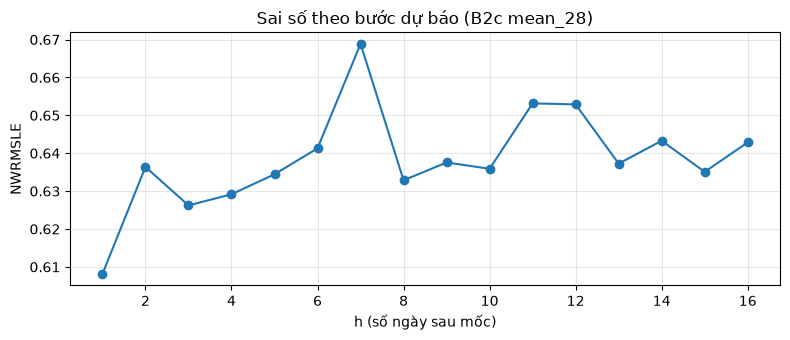

3013

In [48]:
valid_path = files_by_role["valid_last16"][0]
baseline_cols = ["y", "w", "perishable", "pair_status", "h", "has_history", "dow_last", "mean_7", "mean_14", "mean_28",
                 "dow_mean_4", "dow_mean_8", "item_mean_28"]
bv = pq.read_table(valid_path, columns=baseline_cols).to_pandas()

train_ylog = np.concatenate([pq.read_table(p, columns=["y_log"]).column("y_log").to_numpy() for p in train_paths])
B0_CONSTANT = float(np.nanmean(train_ylog))
del train_ylog

preds = {
    "B-zero": np.zeros(len(bv)),
    "B0 (hằng số)": np.full(len(bv), B0_CONSTANT),
    "B1 dow_last": bv["dow_last"].fillna(0).to_numpy(),
    "B2a mean_7": bv["mean_7"].fillna(0).to_numpy(),
    "B2b mean_14": bv["mean_14"].fillna(0).to_numpy(),
    "B2c mean_28": bv["mean_28"].fillna(0).to_numpy(),
    "B3a dow_mean_4": bv["dow_mean_4"].fillna(0).to_numpy(),
    "B3b dow_mean_8": bv["dow_mean_8"].fillna(0).to_numpy(),
    "B4 dow_mean_8 + item_mean_28": bv["dow_mean_8"].fillna(bv["item_mean_28"]).fillna(0).to_numpy(),
}

baseline_rows = []
for name, pred_log in preds.items():
    pred = np.expm1(np.clip(pred_log, 0, None))
    baseline_rows.append({"baseline": name, "NWRMSLE": nwrmsle(bv["y"], pred, bv["perishable"])})
baseline_df = pd.DataFrame(baseline_rows).sort_values("NWRMSLE").reset_index(drop=True)
display(baseline_df.round(5))

BEST_BASELINE = baseline_df.iloc[0]["baseline"]
best_pred = np.expm1(np.clip(preds[BEST_BASELINE], 0, None))
print("Baseline tốt nhất:", BEST_BASELINE)

def breakdown(group_series, label):
    out = []
    for key, idx in bv.groupby(group_series).groups.items():
        idx = np.asarray(idx)
        out.append({label: key, "rows": len(idx), "NWRMSLE": nwrmsle(bv["y"].to_numpy()[idx], best_pred[idx], bv["perishable"].to_numpy()[idx])})
    return pd.DataFrame(out)

by_h = breakdown(bv["h"], "h")
by_perishable = breakdown(bv["perishable"], "perishable")
by_status = breakdown(bv["pair_status"], "pair_status")
by_status["nhóm"] = by_status["pair_status"].map(STATUS_NAMES)
display(by_perishable.round(4)); display(by_status.round(4))

plt.figure(figsize=(8, 3.5))
plt.plot(by_h["h"], by_h["NWRMSLE"], marker="o")
plt.xlabel("h (số ngày sau mốc)"); plt.ylabel("NWRMSLE"); plt.title(f"Sai số theo bước dự báo ({BEST_BASELINE})"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

baseline_df.to_csv(REPORT_TABLE_DIR / "03_baselines.csv", index=False)
del bv, preds
gc.collect()

Trung bình 28 ngày có điểm V1 khoảng **0,6386**, tốt nhất trong các quy tắc đã thử. Đây là mốc so sánh; cặp mới chưa được đánh giá vì V1 chỉ gồm cặp có lịch sử.


## 23. Danh mục feature

Lưu tên, nhóm, mô tả, kiểu dữ liệu, tỷ lệ thiếu và tương quan Spearman với target trên mẫu V1. Tương quan không thay cho điểm đánh giá mô hình.


In [49]:
DESCRIPTIONS = {
    "h": "Bước dự báo (1..HORIZON)", "dow": "Thứ trong tuần của ngày mục tiêu (0 = Thứ Hai)", "dom": "Ngày trong tháng",
    "month": "Tháng", "woy": "Tuần ISO", "days_to_month_end": "Số ngày tới cuối tháng", "is_payday15": "Ngày 15 hoặc ngày cuối tháng",
    "is_jan1": "Ngày 01/01", "is_dec24_31": "Từ 24 đến 31/12", "days_to_xmas": "Số ngày tới 25/12 gần nhất (tối đa 60)",
    "is_nat_hol": "Lễ quốc gia hiệu lực", "is_reg_hol": "Lễ vùng (khớp state cửa hàng)", "is_loc_hol": "Lễ địa phương (khớp city cửa hàng)",
    "is_event_nat": "Sự kiện quốc gia (Event)", "is_workday": "Ngày làm việc bù (Work Day)",
    "days_to_nat_hol": "Số ngày tới lễ quốc gia kế tiếp (tối đa 30)", "days_since_nat_hol": "Số ngày kể từ lễ quốc gia gần nhất (tối đa 30)",
    "store_type": "Loại cửa hàng (mã)", "store_cluster": "Cụm cửa hàng", "store_state": "Tỉnh (mã)", "store_city": "Thành phố (mã)",
    "item_family": "Nhóm hàng (mã)", "item_class": "Lớp hàng", "perishable": "Hàng mau hỏng",
    "mean_3": "Trung bình log1p(y) 3 ngày cuối", "mean_7": "Trung bình log1p(y) 7 ngày cuối", "mean_14": "Trung bình log1p(y) 14 ngày cuối",
    "mean_28": "Trung bình log1p(y) 28 ngày cuối", "mean_56": "Trung bình log1p(y) 56 ngày cuối", "mean_112": "Trung bình log1p(y) 112 ngày cuối",
    "mean_224": "Trung bình log1p(y) 224 ngày cuối", "std_28": "Độ lệch chuẩn 28 ngày", "max_28": "Giá trị lớn nhất 28 ngày",
    "days_since_last_sale": "Số ngày kể từ lần bán cuối (tối đa LOOKBACK)", "pair_age_days": "Số ngày kể từ lần bán đầu tiên",
    "trend_7_28": "mean_7 trừ mean_28", "trend_28_112": "mean_28 trừ mean_112",
    "promo_days_7": "Số ngày có khuyến mãi (trong 7 ngày cuối, chỉ tính ngày có dòng bán)", "promo_days_28": "Như trên, 28 ngày",
    "promo_share_sale_days_28": "Tỷ lệ ngày bán có khuyến mãi trong 28 ngày cuối",
    "dow_last": "Giá trị lần gần nhất cùng thứ trong tuần", "dow_mean_4": "Trung bình 4 lần cùng thứ gần nhất",
    "dow_mean_8": "Trung bình 8 lần cùng thứ gần nhất", "dow_mean_16": "Trung bình 16 lần cùng thứ gần nhất",
    "dow_act_8": "Tỷ lệ có bán trong 8 lần cùng thứ gần nhất", "dow_ratio_8": "dow_mean_8 trừ mean_56",
    "item_mean_28": "Mức bán trung bình 28 ngày của item trên các cửa hàng", "item_act_28": "Tần suất bán trung bình của item",
    "item_nstores_active_28": "Số cửa hàng đang bán item", "store_mean_28": "Mức bán trung bình 28 ngày của cửa hàng",
    "store_nitems_active_28": "Số mặt hàng đang bán của cửa hàng", "family_store_mean_28": "Mức bán trung bình của nhóm hàng tại cửa hàng",
    "class_mean_28": "Mức bán trung bình của lớp hàng", "item_age_days": "Số ngày kể từ lần bán đầu tiên của item",
    "store_dow_idx": "Hệ số thứ trong tuần của cửa hàng", "store_tx_7": "Số giao dịch TB 7 ngày cuối của cửa hàng",
    "store_tx_28": "Số giao dịch TB 28 ngày cuối của cửa hàng", "store_tx_ratio": "store_tx_7 chia store_tx_28",
    "store_age_days": "Tuổi cửa hàng (ngày)", "promo_t": "Có khuyến mãi vào ngày mục tiêu", "promo_h_sum": "Số ngày khuyến mãi của cặp trong horizon",
    "item_promo_share_t": "Tỷ lệ cặp của item có khuyến mãi ngày mục tiêu", "store_promo_share_t": "Tỷ lệ cặp của cửa hàng có khuyến mãi ngày mục tiêu",
    "promo_known_t": "Ngày mục tiêu thuộc giai đoạn đã ghi nhận khuyến mãi", "oil_T": "Giá dầu tại mốc (điền tiến)", "oil_chg_28": "Biến động giá dầu 28 ngày",
    "has_history": "Cặp có lịch sử tại mốc", "pair_status": "Nhóm cặp (0..3)",
}
META_COLS = ["store_nbr", "item_nbr", "origin", "date", "id", "y", "y_log", "w"]
FUTURE_PROMO = ["promo_t", "promo_h_sum", "item_promo_share_t", "store_promo_share_t", "promo_known_t"]


def group_of(name):
    if name in META_COLS:
        return "meta/nhãn"
    if name in ("oil_T", "oil_chg_28"):
        return "exploratory"
    if name in FUTURE_PROMO:
        return "khuyến mãi tương lai (rủi ro)"
    if name.startswith("promo"):
        return "khuyến mãi lịch sử"
    if name.startswith("dow_") and name != "dow":
        return "cùng thứ trong tuần"
    if name in ("dow", "dom", "month", "woy", "h", "days_to_month_end", "is_payday15", "is_jan1", "is_dec24_31", "days_to_xmas") or name.startswith("is_") or "nat_hol" in name:
        return "lịch / ngày lễ"
    if name in ("store_type", "store_cluster", "store_state", "store_city", "item_family", "item_class", "perishable"):
        return "metadata"
    if name.startswith(("item_", "store_", "family_", "class_")):
        return "phân cấp / cửa hàng"
    if name in ("has_history", "pair_status"):
        return "trạng thái cặp"
    return "lịch sử cặp"


sample_v = read_columns(files_by_role["valid_last16"], [c for c in schema_names], max_rows=300_000)
feature_names = [c for c in schema_names if c not in META_COLS]

corr_rows = []
for name in feature_names:
    col = sample_v[name]
    rho = col.corr(sample_v["y_log"], method="spearman") if col.nunique(dropna=True) > 1 else np.nan
    corr_rows.append({"feature": name, "nhóm": group_of(name), "mô tả": DESCRIPTIONS.get(name, ""),
                      "dtype": str(dataset_all.schema.field(name).type), "null_pct": col.isna().mean() * 100,
                      "rủi ro": ("khuyến mãi chỉ quan sát khi có dòng bán ở train (mục 11.3)" if name in FUTURE_PROMO[:4] else ""),
                      "spearman_với_y_log": rho})
catalog_df = pd.DataFrame(corr_rows)
catalog_df["|rho|"] = catalog_df["spearman_với_y_log"].abs()
catalog_df = catalog_df.sort_values(["nhóm", "|rho|"], ascending=[True, False]).drop(columns="|rho|").reset_index(drop=True)
catalog_df.to_csv(REPORT_TABLE_DIR / "03_feature_catalog.csv", index=False)

print(f"{len(feature_names)} feature | nhóm:")
display(catalog_df.groupby("nhóm").size().rename("số feature").to_frame().T)
display(catalog_df.sort_values("spearman_với_y_log", key=lambda s: s.abs(), ascending=False).head(20)[["feature", "nhóm", "null_pct", "spearman_với_y_log"]].round(3))
del sample_v
gc.collect()

75 feature | nhóm:


nhóm,cùng thứ trong tuần,exploratory,khuyến mãi lịch sử,khuyến mãi tương lai (rủi ro),lịch / ngày lễ,lịch sử cặp,metadata,phân cấp / cửa hàng,trạng thái cặp
số feature,6,2,3,5,17,20,7,13,2


,feature,nhóm,null_pct,spearman_với_y_log
33,mean_28,lịch sử cặp,0.000,0.768
34,mean_14,lịch sử cặp,0.000,0.767
35,mean_56,lịch sử cặp,0.000,0.760
36,mean_7,lịch sử cặp,0.000,0.760
0,dow_mean_8,cùng thứ trong tuần,0.047,0.748
37,mean_112,lịch sử cặp,0.000,0.746
1,dow_mean_4,cùng thứ trong tuần,0.047,0.742
2,dow_mean_16,cùng thứ trong tuần,0.047,0.741
38,mean_3,lịch sử cặp,0.000,0.740
39,act_28,lịch sử cặp,0.000,0.738


0

Tỷ lệ thiếu trên V1 thấp hơn test vì V1 chỉ có cặp đã biết. Với cặp mới, các feature lịch sử là NaN. Việc model đọc được NaN không có nghĩa đã học cách dự báo tốt cho nhóm này.

`promo_share_sale_days_28` có thể là NaN khi không có trạng thái được ghi nhận. Số ngày khuyến mãi có thể bằng 0 với cặp có lịch sử.


## 24. Heatmap tương quan

Tương quan Spearman trên tối đa 50.000 dòng V1. Tương quan cao không chứng minh quan hệ nhân quả hay bảo đảm mô hình dự báo tốt.


Số dòng dùng cho heatmap: 49705


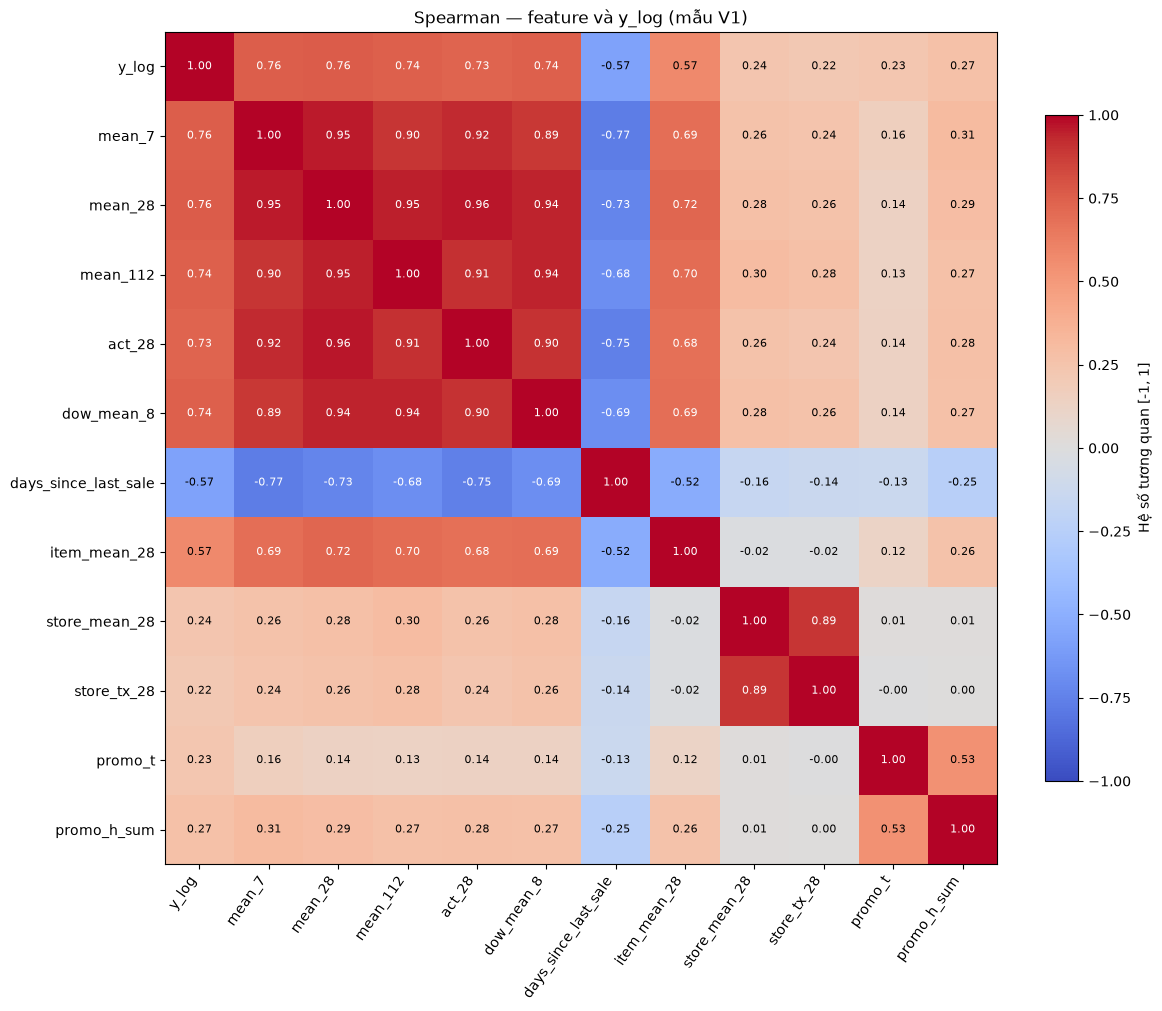

In [50]:
def draw_correlation_heatmap(corr, ax, title):
    values = corr.to_numpy(dtype=float)
    image = ax.imshow(np.ma.masked_invalid(values), cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=55, ha='right')
    ax.set_yticks(range(len(corr.index)), labels=corr.index)
    ax.set_title(title)
    for i in range(len(corr.index)):
        for j in range(len(corr.columns)):
            v=values[i,j]
            label=f'{v:.2f}' if np.isfinite(v) else 'NA'
            ax.text(j,i,label,ha='center',va='center',fontsize=8,
                    color='white' if np.isfinite(v) and abs(v)>.65 else 'black')
    return image

heatmap_cols = ['y_log','mean_7','mean_28','mean_112','act_28','dow_mean_8',
    'days_since_last_sale','item_mean_28','store_mean_28','store_tx_28','promo_t','promo_h_sum']
heatmap_sample = read_columns(files_by_role['valid_last16'], heatmap_cols, max_rows=50_000)
if len(heatmap_sample)>50_000:
    heatmap_sample=heatmap_sample.sample(50_000,random_state=SEED)
heatmap_corr=heatmap_sample.corr(method='spearman', min_periods=100)
print('Số dòng dùng cho heatmap:',len(heatmap_sample))
fig, ax = plt.subplots(figsize=(12, 10), constrained_layout=True)
im=draw_correlation_heatmap(heatmap_corr, ax, 'Spearman — feature và y_log (mẫu V1)')
fig.colorbar(im, ax=ax, shrink=.8, label='Hệ số tương quan [-1, 1]')
plt.show()
heatmap_corr.to_csv(REPORT_TABLE_DIR/'03_feature_correlation_spearman.csv')
del heatmap_sample


## 25. Cấu hình cho bước baseline

Lưu fold, quy tắc chọn mốc train, danh sách nhóm feature và cấu hình đọc dữ liệu trong `reports/03_config.json`. Ước tính bộ nhớ chưa gồm toàn bộ chi phí huấn luyện.


In [51]:
valid_last = run_plan[run_plan["role"] == "valid_last16"].iloc[0]["origin"]
folds = [{"fold": "V1_last16", "valid_origin": valid_last, "valid_role": "valid_last16"}]
if (plan_df["role"] == "valid_seasonal").any():
    folds.append({"fold": "V2_seasonal", "valid_origin": SEASONAL_VALID_ORIGIN, "valid_role": "valid_seasonal"})
folds_df = pd.DataFrame(folds)

train_manifest = manifest[manifest["role"] == "train"].copy()
rows = []
for f in folds:
    usable = train_manifest[train_manifest["origin"] + pd.Timedelta(days=HORIZON) <= f["valid_origin"]]
    rows.append({"fold": f["fold"], "valid_origin": f["valid_origin"], "train_origins": len(usable), "train_rows": int(usable["rows"].sum()),
                 "first_train_origin": usable["origin"].min(), "last_train_origin": usable["origin"].max()})
fold_summary = pd.DataFrame(rows)
display(fold_summary)

n_features = len(feature_names)
total_train_rows = int(train_manifest["rows"].sum())
est_gb = total_train_rows * n_features * 4 / 1024**3
print(f"Dữ liệu huấn luyện: {total_train_rows:,} dòng x {n_features} feature x 4 byte ≈ {est_gb:.2f} GB (float32, trước khi LightGBM tạo bản nhị phân hóa)")
if psutil is not None:
    avail = psutil.virtual_memory().available / 1024**3
    print(f"RAM khả dụng hiện tại: {avail:.2f} GB ->", "OK" if est_gb < 0.5 * avail else "CÓ THỂ THIẾU RAM: giảm TARGET_TRAIN_ROWS, chọn nhóm feature, hoặc lọc theo cửa sổ thời gian ở notebook 04")


def load_features(roles=("train",), columns=None, origin_min=None, origin_max=None, max_rows=None, seed=SEED):
    # Đọc bảng feature theo vai trò và khoảng ngày mốc. Dùng ở notebook 04.
    paths = []
    for role in roles:
        paths.extend(files_by_role.get(role, []))
    parts = []
    for p in paths:
        o = pd.Timestamp(p.stem.split("_")[-1])            # tên file có dạng <role>_YYYYMMDD
        if (origin_min is not None and o < origin_min) or (origin_max is not None and o > origin_max):
            continue
        parts.append(pq.read_table(p, columns=columns).to_pandas())
    out = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=columns)
    if max_rows is not None and len(out) > max_rows:
        out = out.sample(max_rows, random_state=seed).reset_index(drop=True)
    return out


demo = load_features(("valid_last16",), columns=["origin", "h", "y_log"], max_rows=1000)
print("Kiểm thử load_features:", demo.shape)

,fold,valid_origin,train_origins,train_rows,first_train_origin,last_train_origin
0,V1_last16,2017-07-30,53,2905662,2015-06-11,2017-07-04
1,V2_seasonal,2016-08-15,26,1301649,2015-06-11,2016-07-18


Dữ liệu huấn luyện: 2,970,590 dòng x 75 feature x 4 byte ≈ 0.83 GB (float32, trước khi LightGBM tạo bản nhị phân hóa)
RAM khả dụng hiện tại: 1.11 GB -> CÓ THỂ THIẾU RAM: giảm TARGET_TRAIN_ROWS, chọn nhóm feature, hoặc lọc theo cửa sổ thời gian ở notebook 04
Kiểm thử load_features: (1000, 3)


In [52]:
config = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED, "horizon": HORIZON, "lookback": LOOKBACK, "windows": WINDOWS, "dow_occurrences": DOW_OCCURRENCES,
    "origin_step_days": ORIGIN_STEP_DAYS, "train_origin_start": TRAIN_ORIGIN_START.isoformat(), "test_origin": TEST_ORIGIN.isoformat(),
    "quake_window": [QUAKE_START.isoformat(), QUAKE_END.isoformat()],
    "target_train_rows": TARGET_TRAIN_ROWS, "train_pair_frac": TRAIN_PAIR_FRAC,
    "feature_dir": str(FEATURE_DIR.relative_to(PROJECT_ROOT)),
    "target": "y_log = log1p(clip(unit_sales, 0))", "weight": "w (perishable = 1.25, còn lại 1.0)",
    "train_origin_rule": "mốc huấn luyện T_tr dùng cho fold F nếu T_tr + HORIZON <= T_F",
    "folds": folds_df.to_dict(orient="records"),
    "feature_groups": catalog_df.groupby("nhóm")["feature"].apply(list).to_dict(),
    "meta_columns": META_COLS, "status_names": STATUS_NAMES,
    "baseline_best": {"name": BEST_BASELINE, "nwrmsle": float(baseline_df.iloc[0]["NWRMSLE"])},
}
(REPORT_DIR / "03_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Đã lưu reports/03_config.json")

Đã lưu reports/03_config.json


## 26. Lưu báo cáo

Ghi kiểm tra cấu trúc, sai khác tính độc lập, phân phối nhãn và baseline vào `reports/03_feature_engineering_report.json`.


In [53]:
def to_jsonable(value):
    if isinstance(value, dict):
        return {str(k): to_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(v) for v in value]
    if isinstance(value, pd.DataFrame):
        return to_jsonable(value.to_dict(orient="records"))
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return None if np.isnan(value) else float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    return value


report = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "n_features": n_features,
    "manifest": manifest,
    "structure_checks": checks_df,
    "bruteforce_max_abs_diff": float(comparable["abs_diff"].max()),
    "leakage_perturbation_test": "PASS",
    "label_summary": label_df,
    "pair_status_test": status_table,
    "baselines": baseline_df,
    "psi_top": psi_df.head(10),
    "fold_summary": fold_summary,
    "estimated_train_memory_gb": est_gb,
}
(REPORT_DIR / "03_feature_engineering_report.json").write_text(json.dumps(to_jsonable(report), ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu reports/03_feature_engineering_report.json")

Đã lưu reports/03_feature_engineering_report.json


## 27. Kết quả và giới hạn

Đã tạo 75 feature. Các kiểm tra cấu trúc, tính độc lập và nhiễu tương lai đã chạy qua trong phạm vi kiểm tra.

- Cặp mới chiếm khoảng 21% dòng test nhưng chưa có trong validation.
- Ngày không có dòng được coi là 0; chưa so sánh đầy đủ với cách bỏ qua.
- Nhãn store-day vắng bị loại, nhưng lịch sử vẫn dùng ngày vắng bằng 0.
- Khuyến mãi tương lai có rủi ro do cách ghi nhận dòng bán.
- Các mốc train có horizon chồng lấn, nên chia fold theo thời gian.
- Cần kiểm tra thêm feature phân cấp và sai khác NaN.

Notebook 04 tính baseline trên hai fold; notebook 05 huấn luyện mô hình. Heatmap tương quan nằm ở mục 24.
